# Tests for Categorical Data and Proportions

Many of the most important questions in practice are about **categories and proportions**, not averages: *Did the new checkout page increase the conversion rate? Is a symptom more common in one group? Did more people agree after the campaign?*

This lesson covers the toolkit for categorical outcomes: tests for one and two proportions, risk measures, the chi-square test of independence with effect sizes and residuals, Fisher's exact test for small samples, and McNemar's test for paired yes/no data.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Choosing a Test for Categorical Data

| Situation | Test | R |
|---|---|---|
| One proportion vs a claimed value | exact binomial test / one-proportion z-test | `binom.test()`, `prop.test()` |
| Two independent proportions (A/B test) | two-proportion z-test (= $\chi^2$ on a 2×2 table) | `prop.test()` |
| Two categorical variables, larger tables | chi-square test of independence | `chisq.test()` |
| Small expected counts (< 5) | Fisher's exact test | `fisher.test()` |
| Same subjects, yes/no measured twice | McNemar's test | `mcnemar.test()` |
| One categorical variable vs expected shares | chi-square goodness of fit (Lesson 07) | `chisq.test(x, p = ...)` |

## 2. One Proportion

A shop claims that 10% of visitors buy something. In a sample of 160 visitors, 25 bought ($\hat{p} = 0.156$). Is the true rate higher than 10%?

$$
H_0: p = 0.10 \qquad H_a: p \neq 0.10, \qquad
z = \frac{\hat{p} - p_0}{\sqrt{p_0(1-p_0)/n}}
$$

`binom.test()` computes the **exact** p-value from the binomial distribution; `prop.test()` uses the normal approximation (fine when $np_0$ and $n(1-p_0)$ are at least about 10).

In [2]:
k <- 25; n <- 160; p0 <- 0.10
z <- (k / n - p0) / sqrt(p0 * (1 - p0) / n)
cat(sprintf("p-hat = %.3f, z = %.3f, approximate two-sided p = %.4f\n", k / n, z, 2 * (1 - pnorm(abs(z)))))

binom.test(k, n, p = p0)

p-hat = 0.156, z = 2.372, approximate two-sided p = 0.0177



	Exact binomial test

data:  k and n
number of successes = 25, number of trials = 160, p-value = 0.02416
alternative hypothesis: true probability of success is not equal to 0.1
95 percent confidence interval:
 0.1037418 0.2219562
sample estimates:
probability of success 
               0.15625 


## 3. Two Proportions: an A/B Test

An online shop shows the old checkout page (A) to 2,400 visitors and a new one (B) to 2,350 visitors.

$$
H_0: p_A = p_B, \qquad
z = \frac{\hat{p}_B - \hat{p}_A}{\sqrt{\hat{p}(1-\hat{p})\left(\frac{1}{n_A} + \frac{1}{n_B}\right)}}, \qquad \hat{p} = \frac{k_A + k_B}{n_A + n_B}
$$

Besides the p-value we report three effect measures:

- **Risk difference** (absolute lift): $\hat{p}_B - \hat{p}_A$
- **Relative risk** (relative lift): $\hat{p}_B / \hat{p}_A$
- **Odds ratio**: $\dfrac{\hat{p}_B/(1-\hat{p}_B)}{\hat{p}_A/(1-\hat{p}_A)}$ (the measure logistic regression uses, Lesson 19)

In [3]:
conversions <- c(A = 228, B = 282)
visitors    <- c(A = 2400, B = 2350)
rates <- conversions / visitors

ab <- prop.test(conversions, visitors, correct = FALSE)
ab

rd <- rates["B"] - rates["A"]
rr <- rates["B"] / rates["A"]
or <- (rates["B"] / (1 - rates["B"])) / (rates["A"] / (1 - rates["A"]))
cat(sprintf("Conversion: A = %.2f%%, B = %.2f%%\n", 100 * rates["A"], 100 * rates["B"]))
cat(sprintf("Risk difference (B - A) = %.2f percentage points, 95%% CI [%.2f, %.2f]\n",
            100 * rd, -100 * ab$conf.int[2], -100 * ab$conf.int[1]))
cat(sprintf("Relative lift = %.1f%%  |  Odds ratio = %.3f\n", 100 * (rr - 1), or))


	2-sample test for equality of proportions without continuity correction

data:  conversions out of visitors
X-squared = 7.7431, df = 1, p-value = 0.005392
alternative hypothesis: two.sided
95 percent confidence interval:
 -0.042613424 -0.007386576
sample estimates:
prop 1 prop 2 
 0.095  0.120 


Conversion: A = 9.50%, B = 12.00%


Risk difference (B - A) = 2.50 percentage points, 95% CI [0.74, 4.26]


Relative lift = 26.3%  |  Odds ratio = 1.299


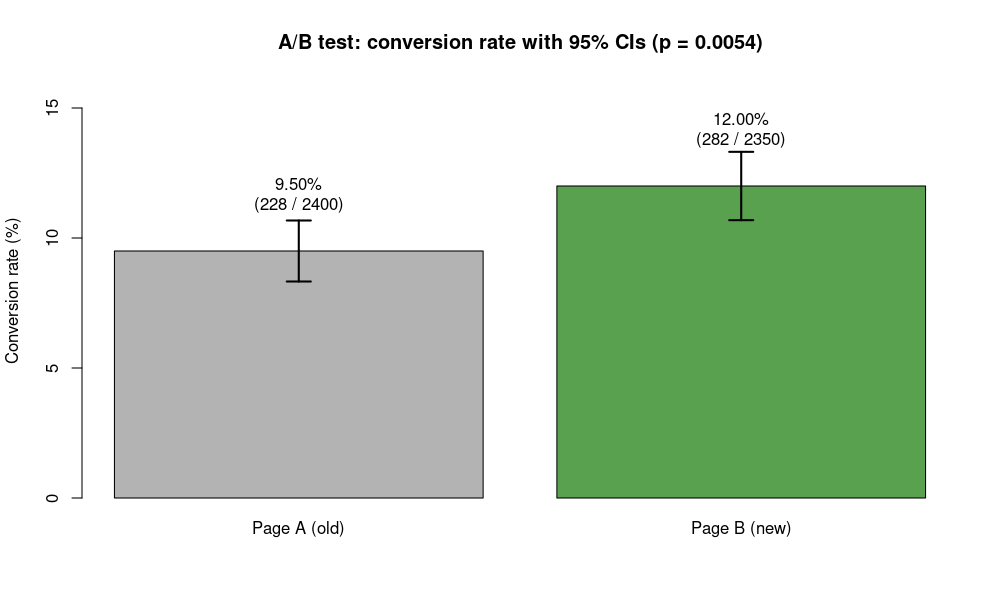

In [4]:
se <- sqrt(rates * (1 - rates) / visitors)
bp <- barplot(100 * rates, col = c("grey70", "#59A14F"), ylim = c(0, 16), names.arg = c("Page A (old)", "Page B (new)"),
              main = sprintf("A/B test: conversion rate with 95%% CIs (p = %.4f)", ab$p.value), ylab = "Conversion rate (%)")
arrows(bp, 100 * (rates - 1.96 * se), bp, 100 * (rates + 1.96 * se), angle = 90, code = 3, length = 0.12, lwd = 2)
text(bp, 100 * rates + 2.2, sprintf("%.2f%%\n(%d / %d)", 100 * rates, conversions, visitors))

*Insight: "Page B is 26% better" (relative lift) sounds much bigger than "+2.5 percentage points" (absolute lift), although both describe the same result. Report both, so readers aren't misled by whichever sounds more impressive.*

## 4. Chi-square Test of Independence

Are two categorical variables related? Below: a survey of 500 people about their preferred streaming plan by age group. Under $H_0$ (independence), the expected count in each cell is

$$
E_{ij} = \frac{(\text{row total}_i)(\text{column total}_j)}{N}, \qquad
\chi^2 = \sum_{i,j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}, \qquad df = (r-1)(c-1)
$$

After a significant result, two more tools tell the full story:

- **Standardised residuals** $\frac{O - E}{\sqrt{E \cdot (1 - \text{row share})(1 - \text{col share})}}$ show *which cells* drive the association (|value| > 2 is notable).
- **Cramér's V** $= \sqrt{\dfrac{\chi^2}{N \cdot (\min(r, c) - 1)}}$ measures the *strength* of the association on a 0–1 scale (≈0.1 small, 0.3 medium, 0.5 large).

In [5]:
plans <- matrix(c(60, 45, 25,
                  55, 70, 45,
                  30, 60, 110),
                nrow = 3, byrow = TRUE,
                dimnames = list(Age = c("18-29", "30-49", "50+"), Plan = c("Basic", "Standard", "Premium")))
print(addmargins(plans))

chi <- chisq.test(plans)
chi
cat("\nExpected counts under independence:\n"); print(round(chi$expected, 1))
cat("\nStandardised residuals:\n");             print(round(chi$stdres, 2))

cramers_v <- sqrt(chi$statistic / (sum(plans) * (min(dim(plans)) - 1)))
cat("\nCramer's V =", round(cramers_v, 3), "\n")

       Plan
Age     Basic Standard Premium Sum
  18-29    60       45      25 130
  30-49    55       70      45 170
  50+      30       60     110 200
  Sum     145      175     180 500



	Pearson's Chi-squared test

data:  plans
X-squared = 65.152, df = 4, p-value = 2.39e-13



Expected counts under independence:


       Plan
Age     Basic Standard Premium
  18-29  37.7     45.5    46.8
  30-49  49.3     59.5    61.2
  50+    58.0     70.0    72.0



Standardised residuals:


       Plan
Age     Basic Standard Premium
  18-29  5.01    -0.11   -4.63
  30-49  1.19     2.08   -3.19
  50+   -5.63    -1.91    7.23



Cramer's V = 0.255 


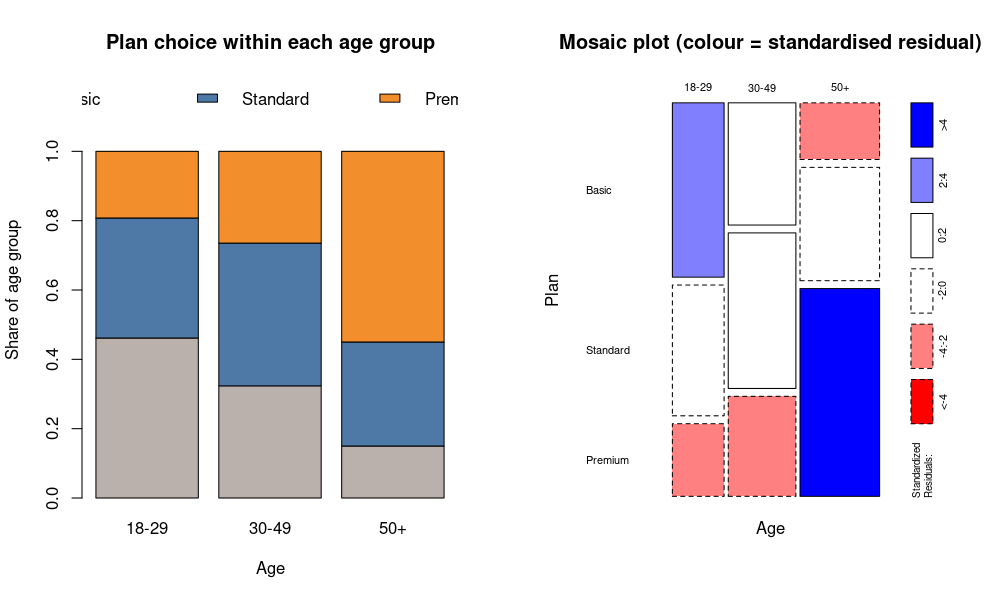

In [6]:
par(mfrow = c(1, 2))
barplot(t(prop.table(plans, 1)), beside = FALSE, col = c("#BAB0AC", "#4E79A7", "#F28E2B"), ylim = c(0, 1.2),
        main = "Plan choice within each age group", ylab = "Share of age group", xlab = "Age", yaxt = "n")
axis(2, at = seq(0, 1, 0.2))
legend("top", colnames(plans), fill = c("#BAB0AC", "#4E79A7", "#F28E2B"), horiz = TRUE, bty = "n")
mosaicplot(plans, shade = TRUE, main = "Mosaic plot (colour = standardised residual)", las = 1)

*Insight: The mosaic plot colours each cell by its residual. Blue cells have more people than independence predicts, red cells fewer. Here older customers lean strongly towards Premium and younger ones towards Basic, which a single $\chi^2$ p-value can't tell you.*

## 5. Fisher's Exact Test: The Lady Tasting Tea

The chi-square approximation needs expected counts of roughly 5 or more in every cell. For small tables, **Fisher's exact test** computes the exact probability of the observed table (and more extreme ones) given the row and column totals.

The classic example comes from Ronald Fisher himself: a colleague claimed she could tell whether milk was poured before or after the tea. She was given 8 cups (4 of each) and had to pick the 4 "milk first" cups.

In [7]:
tea <- matrix(c(3, 1,
                1, 3), nrow = 2, byrow = TRUE,
              dimnames = list(Truth = c("Milk first", "Tea first"), Guess = c("Milk first", "Tea first")))
print(tea)
fisher.test(tea, alternative = "greater")

cat("Expected counts are only", unique(as.vector(suppressWarnings(chisq.test(tea))$expected)), "-> chi-square would be unreliable here.\n")
cat("P(all 4 correct by pure guessing) = 1 / choose(8, 4) =", round(1 / choose(8, 4), 4), "\n")

            Guess
Truth        Milk first Tea first
  Milk first          3         1
  Tea first           1         3



	Fisher's Exact Test for Count Data

data:  tea
p-value = 0.2429
alternative hypothesis: true odds ratio is greater than 1
95 percent confidence interval:
 0.3135693       Inf
sample estimates:
odds ratio 
  6.408309 


Expected counts are only 2 -> chi-square would be unreliable here.


P(all 4 correct by pure guessing) = 1 / choose(8, 4) = 0.0143 


With 3 of 4 correct, $p \approx 0.24$, which isn't convincing. Only a perfect 4/4 would have been significant ($p = 1/70 \approx 0.014$). Small experiments can only detect very strong effects (see Lesson 14).

## 6. McNemar's Test for Paired Yes/No Data

The same 200 people were asked "Would you buy our product?" before and after seeing an advert. The answers are **paired**, so a chi-square test of independence is wrong. McNemar's test uses only the people who **changed** their answer:

$$
\chi^2 = \frac{(b - c)^2}{b + c}
$$

where $b$ = changed from No to Yes and $c$ = changed from Yes to No.

In [8]:
advert <- matrix(c(48, 12,
                   35, 105), nrow = 2, byrow = TRUE,
                 dimnames = list(Before = c("Yes", "No"), After = c("Yes", "No")))
print(advert)
cat(sprintf("Yes before: %.1f%%  ->  Yes after: %.1f%%\n",
            100 * sum(advert["Yes", ]) / sum(advert), 100 * sum(advert[, "Yes"]) / sum(advert)))
mcnemar.test(advert)

      After
Before Yes  No
   Yes  48  12
   No   35 105


Yes before: 30.0%  ->  Yes after: 41.5%



	McNemar's Chi-squared test with continuity correction

data:  advert
McNemar's chi-squared = 10.298, df = 1, p-value = 0.001332


## 7. A Warning About Aggregated Tables

Combining tables across groups can **reverse** an association. This is called Simpson's paradox. Always ask whether a third variable (department, hospital, age group) should be held constant. The end-to-end case study in **Lesson 23** analyses a famous real example: the 1973 UC Berkeley admissions data.

## Real-World Use Case or Analogy

- **A/B testing**: every large website runs two-proportion tests continuously: button colours, prices, recommendation algorithms.
- **Medicine**: "Is the infection rate lower with the new treatment?" Here the relative risk and the risk difference carry very different messages to patients.
- **Survey analysis**: chi-square tests and Cramér's V show whether opinions differ by region, age or income.
- **McNemar**: before/after polling of the same people, or comparing two diagnostic tests on the same patients.

A contingency table is like a **seating chart at a wedding**. If guests sat completely at random, each table would mix families in proportion to their size (the expected counts). The chi-square test asks whether the actual seating is too far from random to be chance, and the residuals show which families clustered together.